mps
torch.Size([5000, 2])
torch.float32


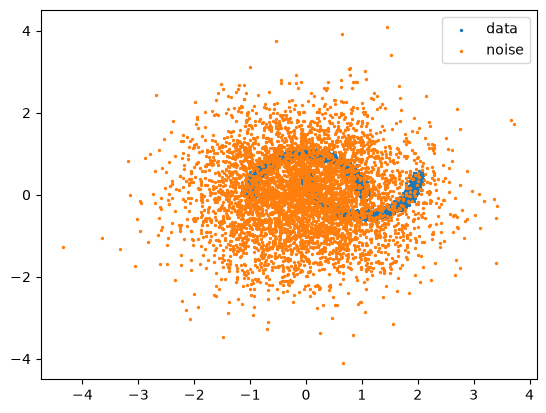

In [62]:
#make moon example
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(device)

data, _ = make_moons(n_samples=5000, noise=0.05, random_state=42)
data_tensor = torch.tensor(data).float()
print(data_tensor.shape)
print(data_tensor.dtype)
#only x, only y
plt.scatter(data_tensor[:, 0],data_tensor[:, 1], s=2, label = "data")

#5000 points, 2 dimension
noise = torch.randn(5000, 2)
plt.scatter(noise[:, 0], noise[:, 1], s=2, label="noise")

plt.legend()
plt.show()


In [63]:
import torch
import torch.nn as nn
class VelocityMLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.layer1 = nn.Linear(3, 128)
        self.relu = nn.ReLU()
        self.layer2 = nn.Linear(128, 128)
        self.layer3 = nn.Linear(128, 2)

    def forward(self, x_t, t):
        x = torch.cat([x_t, t], dim=1) 
        x = self.layer1(x)
        x = self.relu(x)
        x = self.layer2(x)
        x = self.relu(x)
        x = self.layer3(x)
        return x

model = VelocityMLP()
x_t = torch.randn(64, 2)
t = torch.rand(64, 1)
print(model(x_t, t).shape)


torch.Size([64, 2])


In [64]:
import torch

#examplar training - flow matching
model = VelocityMLP().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
data = data_tensor.to(device)

for step in range(5000):

    #torch.randint(min, max, shape)
    idx = torch.randint(0, 5000, (256,))

    #parameters
    x1 = data[idx]
    x0 = torch.randn_like(x1)
    t = torch.rand(256, 1, device=device)

    x_t = (1-t)*x0 + t*x1
    target = x1 - x0
    pred = model(x_t, t)
    loss = ((pred-target)**2).mean()

    #3stepsss
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if step % 500 == 0:
        print(f"step {step}  |  loss {loss.item():.4f}")


step 0  |  loss 1.4362
step 500  |  loss 1.0684
step 1000  |  loss 1.0055
step 1500  |  loss 1.0897
step 2000  |  loss 0.9243
step 2500  |  loss 1.0103
step 3000  |  loss 0.8411
step 3500  |  loss 1.0057
step 4000  |  loss 0.9468
step 4500  |  loss 0.8804


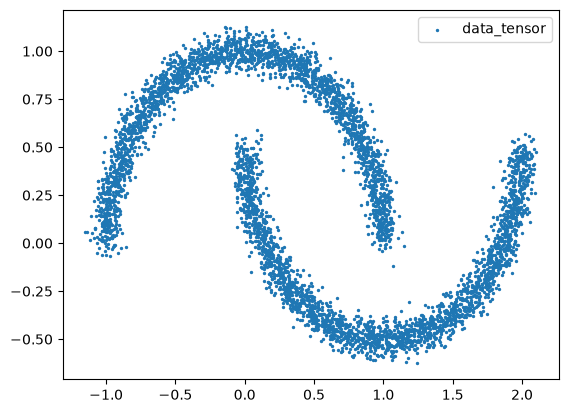

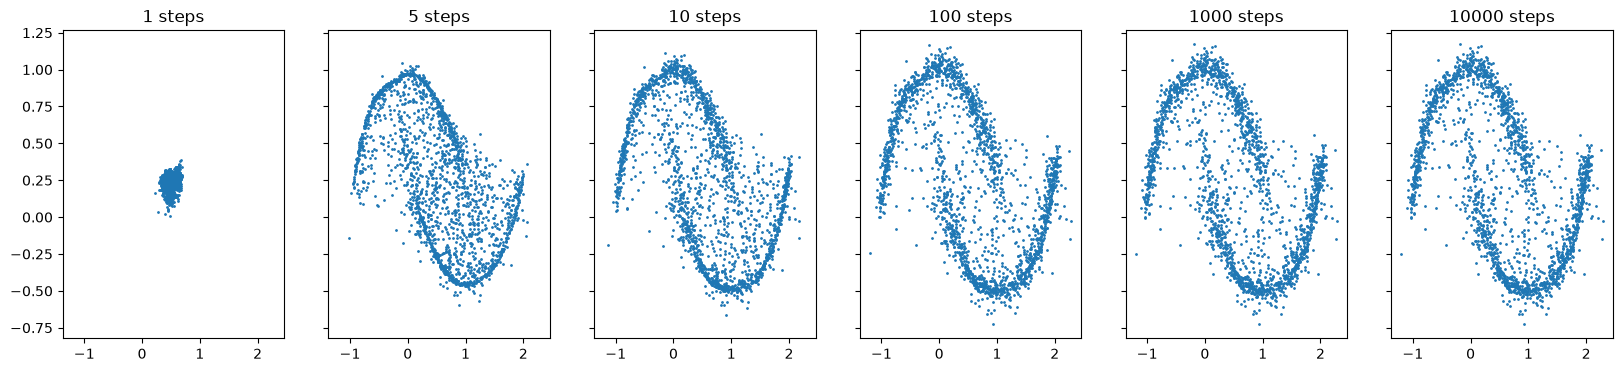

tensor([0.5000, 0.2496])


In [ ]:
def sample(model, n_points, n_steps):
    #do no record gradient
    with torch.no_grad():

        #torch.rand_like(number of points, dimension)
        x = torch.randn(n_points, 2, device=device)
        dt = 1/n_steps
        for i in range(n_steps):
        #     torch.full(  (n_points, 1)  ,   i / n_steps  )
        #                        ↑                  ↑
        #               shape: 1 time/point    value: t for current step 
            t = torch.full((n_points, 1), i/n_steps, device=device)
            v = model(x, t)
            x = x + v * dt
    return x

#sample(model, n_points, steps)
samples = sample(model, 2000, 100)

samples = samples.cpu()

plt.scatter(data_tensor[:,0], data_tensor[:, 1], s=2, label="data_tensor")

plt.legend()
plt.show()

fig, axes = plt.subplots(1, 6, figsize=(20, 4), sharex=True, sharey=True)     

for i, n in enumerate([1, 5, 10, 100, 1000, 10000]):
    torch.manual_seed(0)
    s = sample(model, 2000, n).cpu()
    axes[i].scatter(s[:, 0], s[:, 1], s=1)           
    axes[i].set_title(f"{n} steps")      
    
         
plt.savefig("figures/steps_comparison.png", dpi=150, bbox_inches="tight")
plt.show()  
print(data_tensor.mean(dim=0))




In [78]:
def train(model, n_steps):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    losses = []

    for steps in range(n_steps):
        
    #torch.randint(min, max, shape)
        idx = torch.randint(0, 5000, (256,))
    
        #parameters
        x1 = data[idx]
        x0 = torch.randn_like(x1)
        t = torch.rand(256, 1, device=device)
    
        x_t = (1-t)*x0 + t*x1
        target = x1 - x0
        pred = model(x_t, t)
        loss = ((pred-target)**2).mean()

        losses.append(loss.item())#.item turns it form tensor to a nromal python number
    
        #3stepsss
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
        if step % 500 == 0:
            print(f"step {step}  |  loss {loss.item():.4f}")

    return losses

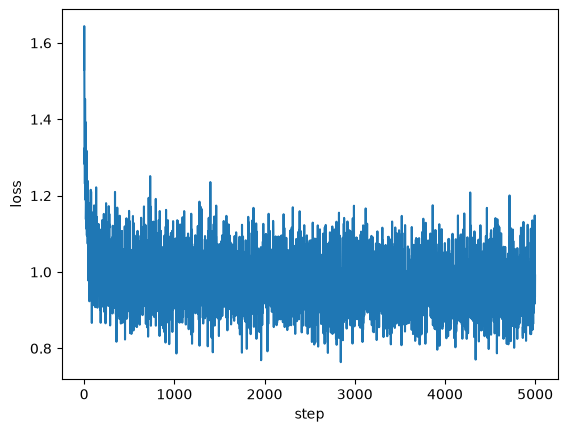

In [79]:
model = VelocityMLP().to(device)
losses = train(model, 5000)


plt.plot(losses)
plt.xlabel("step")
plt.ylabel("loss")
plt.show()